
Hidden width: 16
Accuracy: 0.83
Precision: 0.8742857142857143
Recall: 0.9272727272727272
F1 Score: 0.9

Hidden width: 32
Accuracy: 0.835
Precision: 0.8707865168539326
Recall: 0.9393939393939394
F1 Score: 0.9037900874635568


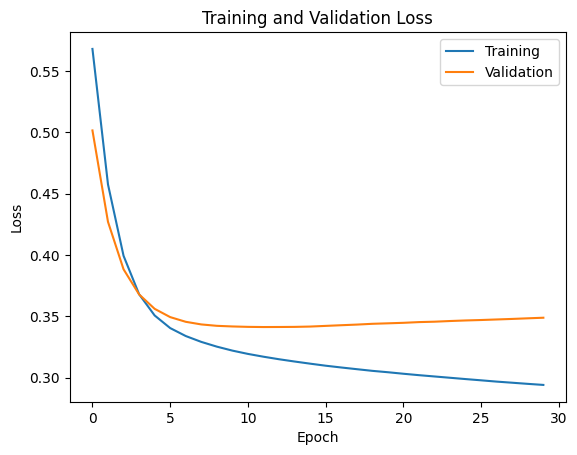

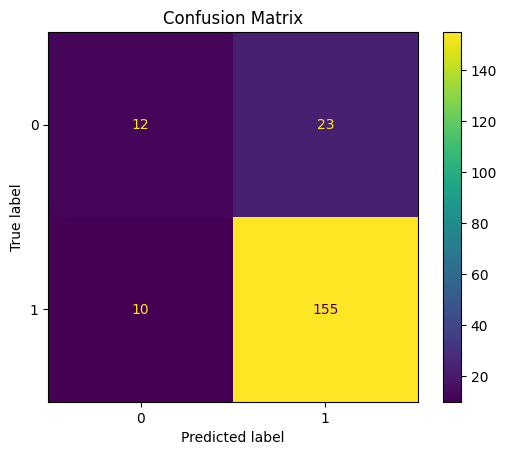


Hidden width: 64
Accuracy: 0.835
Precision: 0.875
Recall: 0.9333333333333333
F1 Score: 0.9032258064516129


In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

np.random.seed(42)
tf.random.set_seed(42)

# Generate sample telecom dataset
n = 1000
df = pd.DataFrame({
    'Tenure': np.random.randint(1, 73, n),
    'MonthlyCharges': np.random.uniform(20, 120, n),
    'Contract': np.random.choice(['Month', 'Year', 'TwoYear'], n),
    'Complaints': np.random.randint(0, 6, n),
    'DataUsage': np.random.uniform(1, 100, n)
})

prob = 1 / (1 + np.exp(-(
    1.5 - 0.04*df.Tenure
    + 0.02*df.MonthlyCharges
    + 0.5*df.Complaints
    - 0.02*df.DataUsage
    + (df.Contract == 'Month')*1.2
)))
df['Churn'] = (np.random.rand(n) < prob).astype(int)

# Encode categorical data
X = pd.get_dummies(df.drop('Churn', axis=1),
                   columns=['Contract'], dtype=int)
y = df['Churn']

# Split and scale data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train MLP with different hidden-layer widths
for width in [16, 32, 64]:
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(width, activation='relu'),
        tf.keras.layers.Dense(width, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

    history = model.fit(
        X_train, y_train, epochs=30, batch_size=32,
        validation_split=0.2, verbose=0
    )

    pred = (model.predict(X_test, verbose=0) > 0.5).astype(int)

    print("\nHidden width:", width)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, zero_division=0))

    if width == 32:
        plt.plot(history.history['loss'], label='Training')
        plt.plot(history.history['val_loss'], label='Validation')
        plt.title('Training and Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.show()

        ConfusionMatrixDisplay(
            confusion_matrix(y_test, pred)
        ).plot()
        plt.title('Confusion Matrix')
        plt.show()
